# 00 · Reference check

Before any material data: confirm the sunlight and eye-sensitivity data load correctly and the metrics behave on cases with obvious answers.

- Sunlight: ASTM G173-03 AM1.5G (via pvlib's copy of the NREL file)
- Eye sensitivity: CIE 1924 photopic V(λ) (via the colour-science package)

The three 'filters' below are idealized test cases, not materials.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from oshn_materials import spectra, mixing, metrics

WL = spectra.GRID
FLUX = spectra.photon_flux(WL, spectra.load_am15g())  # umol m^-2 s^-1 nm^-1
V = spectra.load_photopic()

AM1.5G PAR photon flux (400-700 nm): 1978 umol m^-2 s^-1


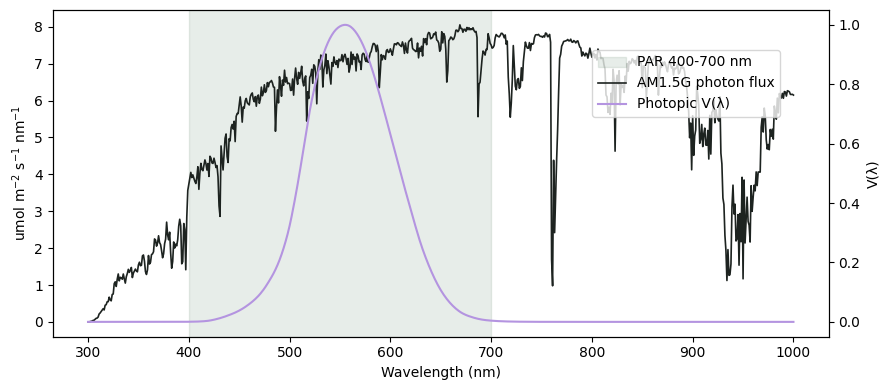

In [2]:
par = (WL >= 400) & (WL <= 700)
print(f"AM1.5G PAR photon flux (400-700 nm): {np.trapezoid(FLUX[par], WL[par]):.0f} umol m^-2 s^-1")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(400, 700, color="#3f6b4a", alpha=0.12, label="PAR 400-700 nm")
ax.plot(WL, FLUX, color="#1d2320", lw=1.2, label="AM1.5G photon flux")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("umol m$^{-2}$ s$^{-1}$ nm$^{-1}$")
ax2 = ax.twinx(); ax2.plot(WL, V, color="#b494e0", lw=1.5, label="Photopic V(λ)"); ax2.set_ylabel("V(λ)")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88)); fig.tight_layout()
fig.savefig("../figures/00_reference_spectra.png", dpi=150)

In [3]:
ideal = {
    "clear glass (T = 1)": np.ones_like(WL),
    "opaque (T = 0)": np.zeros_like(WL),
    "ideal PAR window": ((WL >= 400) & (WL <= 700)).astype(float),
}
pd.DataFrame({name: metrics.summarize(WL, t, FLUX, V) for name, t in ideal.items()}).T.round(3)

,PAR_transmitted_400_700,PAR_transmitted_400_750,AVT,nonPAR_absorbed
clear glass (T = 1),1.0,1.000,1.000,0.0
opaque (T = 0),0.0,0.000,0.000,1.0
ideal PAR window,1.0,0.846,0.999,1.0


The ideal PAR window is the target shape for a crop-friendly absorber: everything in PAR passes, everything outside is captured. Real materials are judged by how close they get.